# Data Collection and Exploration
- **Course:** CSC17104 - Programming for Data Science
- **Class:** 24KHDL
- **Group:** UongMilo
- **Project:** Final Project
- **Date:** November 2026
- **Repository:** [Final Project Repository](https://github.com/NgThanhDat-ne/UongMilo-LoanOrNot)

# Setup

In [1]:
import sys
from IPython.display import display

import pandas as pd 
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter
from matplotlib.ticker import MaxNLocator
import seaborn as sns

print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__)
print("numpy:", np.__version__)
print("matplotlib:", mpl.__version__)
print("seaborn:", sns.__version__)

DATA_DIR = '../data/raw/'

Python: 3.12.16
pandas: 2.3.3
numpy: 2.2.6
matplotlib: 3.10.9
seaborn: 0.13.2


# I. Data Collection
## 1. Dataset Source

- **Original data provider**: U.S. Small Business Administration (SBA)
- **Article authors**: Min Li, Amy Mickel, and Stanley Taylor
- **Original publication venue**: *Journal of Statistics Education*
- **Publication date**: April 5, 2018
- **Original publication and supplementary data**: [https://doi.org/10.1080/10691898.2018.1434342](https://doi.org/10.1080/10691898.2018.1434342)
- **Download source** - [Kaggle: Should This Loan be Approved or Denied?](https://www.kaggle.com/datasets/mirbektoktogaraev/should-this-loan-be-approved-or-denied), uploaded by Mirbek Toktogaraev in March 2020

## 2. Dataset Subject

The National SBA dataset covers small-bussiness lending and loan repayment in the United States. Specifically, the dataset represents a federal loan guarantee program designed to help small businesses access financing. Participating lenders issue the loans, and the SBA guarantees a portion of each loan. If a borrower defaults, the guarantee limits the lender’s potential loss. The records therefore provide a basis for studying how loan and borrower characteristics are associated with default risk.

## 3. Dataset License

The Kaggle release  of the **National SBA dataset** is licensed under **Creative Commons Attribution-ShareAlike 4.0 International (CC BY-SA 4.0)**. This license allows users to copy, redistribute, and adapt the dataset, including for commercial purposes.

When sharing the dataset, users must give appropriate credit, link to the license, and indicate any changes had been made. If they distribute an adapted version, they must use **CC BY-SA 4.0** or a compatible license. They may not impose addtional legal or technical restrictions on uses that the license permits.

## 4. Collection Method

The data comes from administrative records maintained by the U.S. Small Business Admistration for its loan guarantee program. Each row represents one SBA guaranteed loan to the a small business. The published dataset covers loans originating in the 50 U.S. states and Washington, D.C., from 1987 through 2014.

The dataset excludes rejected applications, so the observed repayment outcomes reflect earlier lending decisions. Near the end of the study period, early defaults may be overrepresented because some loans that would eventually be repaid were still active when the observation period ended.

## 5. Choosing Motivation

We chose this dataset to investigate which loan and business characteristics are associated with default in a real small-business lending program. Its size and historical coverage let us compare outcomes across industries, states, and years and test how well models trained on earlier loans predict outcomes for later loans. **(need to be justify again after done analysis)**

We also chose this dataset to explore a practical question in economics and finance: how lenders can assess credit risk when lending to small businesses. Working with real loan records helps us understand how data can inform lending decisions while building practical skills in cleaning, analyzing, and interpreting financial data. The project also gives us a concrete example of our analytical skills to share with prospective employers.

# II. Dataset Exploration

## 1. Dataset Overview
### Reading dataset
Locate the CSV in the directory and then read identifiers and category codes as strings so ZIP leading zeros and unusual fiscal-year labels survive.

In [2]:
data_path = DATA_DIR + "SBAnational.csv"

if data_path is None:
    raise FileNotFoundError("Place SBAnational.csv in data/raw/ before running this notebook.")
    
code_columns = ["LoanNr_ChkDgt", "Zip", "NAICS", "ApprovalFY", "NewExist",
                "FranchiseCode", "UrbanRural"]

sba_df = pd.read_csv(data_path, dtype={c: "str" for c in code_columns}, low_memory=False)

print("Read dataset successfully")

Read dataset successfully


### Number of Rows and Columns

In [3]:
n_rows, n_cols = sba_df.shape
print(f"The number of rows: {n_rows}")
print(f"The number of columns: {n_cols}")
display(sba_df.head())

The number of rows: 899164
The number of columns: 27


,LoanNr_ChkDgt,Name,City,State,Zip,Bank,BankState,NAICS,ApprovalDate,ApprovalFY,...,RevLineCr,LowDoc,ChgOffDate,DisbursementDate,DisbursementGross,BalanceGross,MIS_Status,ChgOffPrinGr,GrAppv,SBA_Appv
0,1000014003,ABC HOBBYCRAFT,EVANSVILLE,IN,47711,FIFTH THIRD BANK,OH,451120,28-Feb-97,1997,...,N,Y,NaN,28-Feb-99,"$60,000.00",$0.00,P I F,$0.00,"$60,000.00","$48,000.00"
1,1000024006,LANDMARK BAR & GRILLE (THE),NEW PARIS,IN,46526,1ST SOURCE BANK,IN,722410,28-Feb-97,1997,...,N,Y,NaN,31-May-97,"$40,000.00",$0.00,P I F,$0.00,"$40,000.00","$32,000.00"
2,1000034009,"WHITLOCK DDS, TODD M.",BLOOMINGTON,IN,47401,GRANT COUNTY STATE BANK,IN,621210,28-Feb-97,1997,...,N,N,NaN,31-Dec-97,"$287,000.00",$0.00,P I F,$0.00,"$287,000.00","$215,250.00"
3,1000044001,"BIG BUCKS PAWN & JEWELRY, LLC",BROKEN ARROW,OK,74012,1ST NATL BK & TR CO OF BROKEN,OK,0,28-Feb-97,1997,...,N,Y,NaN,30-Jun-97,"$35,000.00",$0.00,P I F,$0.00,"$35,000.00","$28,000.00"
4,1000054004,"ANASTASIA CONFECTIONS, INC.",ORLANDO,FL,32801,FLORIDA BUS. DEVEL CORP,FL,0,28-Feb-97,1997,...,N,N,NaN,14-May-97,"$229,000.00",$0.00,P I F,$0.00,"$229,000.00","$229,000.00"


There are 899164 rows and 27 columns in the dataset. Each row in the dataset represents one loan that a small business have lent from the U.S. Small Business Administration (SBA).

### Columns meaning and data type

The meaning of each column in the dataset:
- `LoanNr_ChkDgt`: Loan identifier / primary key
- `Name`: Borrower name
- `City`: Borrower city
- `State`: Borrower state
- `Zip`: Borrower ZIP code
- `Bank`: Lending bank name
- `BankState`: Lending bank state
- `NAICS`: Industry classification code
- `ApprovalDate`: Date SBA commitment issued
- `ApprovalFY`: Fiscal year of commitment
- `Term`: Loan term in months
- `NoEmp`: Number of business employees
- `NewExist`: 1 = existing business; 2 = new business
- `CreateJob`: Number of jobs created
- `RetainedJob`: Number of jobs retained
- `FranchiseCode`: Franchise identifier; 0 or 1 = no franchise
- `UrbanRural`: 1 = urban; 2 = rural; 0 = undefined
- `RevLineCr`: Revolving credit: Y = yes; N = no
- `LowDoc`: Low-documentation program: Y = yes; N = no
- `ChgOffDate`: Date loan declared in default
- `DisbursementDate`: Date funds disbursed
- `DisbursementGross`: Amount disbursed, USD
- `BalanceGross`: Gross amount outstanding, USD
- `MIS_Status`: CHGOFF = charged off; P I F = paid in full
- `ChgOffPrinGr`: Charged-off principal, USD
- `GrAppv`: Gross loan amount approved by bank, USD
- `SBA_Appv`: SBA-guaranteed approved amount, USD

The raw data type of each column when it has been read by the CSV reader:

In [4]:
display(sba_df.dtypes)

LoanNr_ChkDgt        object
Name                 object
City                 object
State                object
Zip                  object
Bank                 object
BankState            object
NAICS                object
ApprovalDate         object
ApprovalFY           object
Term                  int64
NoEmp                 int64
NewExist             object
CreateJob             int64
RetainedJob           int64
FranchiseCode        object
UrbanRural           object
RevLineCr            object
LowDoc               object
ChgOffDate           object
DisbursementDate     object
DisbursementGross    object
BalanceGross         object
MIS_Status           object
ChgOffPrinGr         object
GrAppv               object
SBA_Appv             object
dtype: object

### Check duplicate and empty rows
We count duplicate rows, empty rows and repeated loan IDs. Two loans can have the same borrower name, so we do not use the name to find duplicate loans.

In [5]:
# Use a copy to keep the original data unchanged.
eda = sba_df.copy()
text_columns = eda.select_dtypes(include=["object", "string"]).columns
for col in text_columns:
    eda[col] = eda[col].str.strip().replace("", pd.NA)

duplicate_count = sba_df.duplicated().sum()
empty_count = eda.isna().all(axis=1).sum()
id_duplicate_count = eda["LoanNr_ChkDgt"].dropna().duplicated().sum()

print("The number of duplicate rows:", duplicate_count)
print("The number of empty rows:", empty_count)
print("The number of repeated loan IDs:", id_duplicate_count)


The number of duplicate rows: 0
The number of empty rows: 0
The number of repeated loan IDs: 0


### Convert money and date columns
Money columns contain dollar signs and commas. We remove them and convert these columns to numbers. We also convert date columns to dates.

Values that cannot be converted become missing values. The table shows how many values failed in each column. We keep unusual years and dates for checking later.

In [6]:
money_cols = ["DisbursementGross", "BalanceGross", "ChgOffPrinGr", "GrAppv", "SBA_Appv"]
date_cols = ["ApprovalDate", "DisbursementDate", "ChgOffDate"]
conversion_errors = {}

for col in money_cols:
    original = eda[col]
    cleaned = original.str.replace("$", "", regex=False).str.replace(",", "", regex=False)
    eda[col] = pd.to_numeric(cleaned, errors="coerce")
    conversion_errors[col] = (original.notna() & eda[col].isna()).sum()

for col in date_cols:
    original = eda[col]
    eda[col] = pd.to_datetime(original, format="%d-%b-%y", errors="coerce")
    conversion_errors[col] = (original.notna() & eda[col].isna()).sum()

# Only use fiscal years written as four digits.
valid_year = eda["ApprovalFY"].str.fullmatch(r"\d{4}", na=False)
eda["ApprovalYear"] = pd.to_numeric(eda["ApprovalFY"].where(valid_year), errors="coerce")
display(pd.Series(conversion_errors, name="Conversion errors").to_frame())
display(eda.loc[~valid_year, "ApprovalFY"].value_counts(dropna=False))
display(eda[date_cols].agg(["min", "max"]))

print("Approval dates after 2014:", (eda["ApprovalDate"].dt.year > 2014).sum())
print("Disbursement before approval:", (eda["DisbursementDate"] < eda["ApprovalDate"]).sum())
print("Charge-off before disbursement:", (eda["ChgOffDate"] < eda["DisbursementDate"]).sum())


,Conversion errors
DisbursementGross,0
BalanceGross,0
ChgOffPrinGr,0
GrAppv,0
SBA_Appv,0
ApprovalDate,0
DisbursementDate,0
ChgOffDate,0


ApprovalFY
1976A    18
Name: count, dtype: int64

,ApprovalDate,DisbursementDate,ChgOffDate
min,1969-01-31,1969-05-22,1988-10-03
max,2068-12-03,2068-11-22,2026-10-22


Approval dates after 2014: 9
Disbursement before approval: 808
Charge-off before disbursement: 10


## 2. Numerical Columns in Dataset

### Summary of numerical columns
We check the mean, median, minimum and maximum of each numerical column. We also count zero and negative values. Loan IDs and category codes are not included because their numbers are labels.

In [7]:
numeric_cols = ["Term", "NoEmp", "CreateJob", "RetainedJob"] + money_cols
numeric = eda[numeric_cols]
summary = numeric.describe().T
summary["Zero values"] = (numeric == 0).sum()
summary["Negative values"] = (numeric < 0).sum()
display(summary.round(2))

# IQR is the distance between the first and third quartiles.
q1 = numeric.quantile(0.25)
q3 = numeric.quantile(0.75)
iqr = q3 - q1
outliers = (numeric < q1 - 1.5 * iqr) | (numeric > q3 + 1.5 * iqr)
z_scores = (numeric - numeric.mean()) / numeric.std().replace(0, np.nan)

outlier_counts = pd.DataFrame({
    "IQR outliers": outliers.sum(),
    "Z-score above 3": (z_scores.abs() > 3).sum(),
    "Possible placeholder values": numeric.isin([-1, 999, 9999]).sum()
})
display(outlier_counts)


,count,mean,std,min,25%,50%,75%,max,Zero values,Negative values
Term,899164.0,110.77,78.86,0.0,60.0,84.0,120.0,569.0,810,0
NoEmp,899164.0,11.41,74.11,0.0,2.0,4.0,10.0,9999.0,6631,0
CreateJob,899164.0,8.43,236.69,0.0,0.0,0.0,1.0,8800.0,629248,0
RetainedJob,899164.0,10.80,237.12,0.0,0.0,1.0,4.0,9500.0,440403,0
DisbursementGross,899164.0,201154.02,287640.85,0.0,42000.0,100000.0,238000.0,11446325.0,196,0
BalanceGross,899164.0,2.99,1442.16,0.0,0.0,0.0,0.0,996262.0,899150,0
ChgOffPrinGr,899164.0,13503.30,65152.29,0.0,0.0,0.0,0.0,3512596.0,737152,0
GrAppv,899164.0,192686.98,283263.39,200.0,35000.0,90000.0,225000.0,5472000.0,0,0
SBA_Appv,899164.0,149488.79,228414.56,100.0,21250.0,61250.0,175000.0,5472000.0,0,0


,IQR outliers,Z-score above 3,Possible placeholder values
Term,158700,183,0
NoEmp,97222,1449,4
CreateJob,148911,677,0
RetainedJob,90667,675,0
DisbursementGross,83643,19319,11
BalanceGross,14,12,0
ChgOffPrinGr,162012,13013,55
GrAppv,85523,19638,0
SBA_Appv,90174,18086,0


### Distribution of numerical columns

Each numerical column is plotted in its own code cell, with bins chosen for its units and observed range. Missing values are omitted; zero values are retained or counted explicitly.

- `Term` uses 12-month bins across its full range.
- `NoEmp`, `CreateJob` and `RetainedJob` use single-unit bins in a main view, with an additional full-range view. The printed counts show how many observations lie beyond the main view.
- `DisbursementGross`, `GrAppv` and `SBA_Appv` use $25,000 bins in their main views and include their full ranges alongside.
- Full-range histograms marked **log1p** plot `log(1 + value)`, with ticks labeled in original units. Equal-width bins on this transformed axis cover wider intervals at larger original values. Their vertical axes also use a log scale to make rare values visible; read the axis labels when comparing heights.
- `BalanceGross` and `ChgOffPrinGr` separate zero amounts from positive amounts. `BalanceGross` has very few positive observations, so these are shown with coarse dollar bins and integer counts. Positive `ChgOffPrinGr` amounts use log-spaced dollar bins and log axes.

The zoomed views are for readability only. No values are removed from `eda`, and the full-range views or separate zero/positive panels account for every non-missing observation.


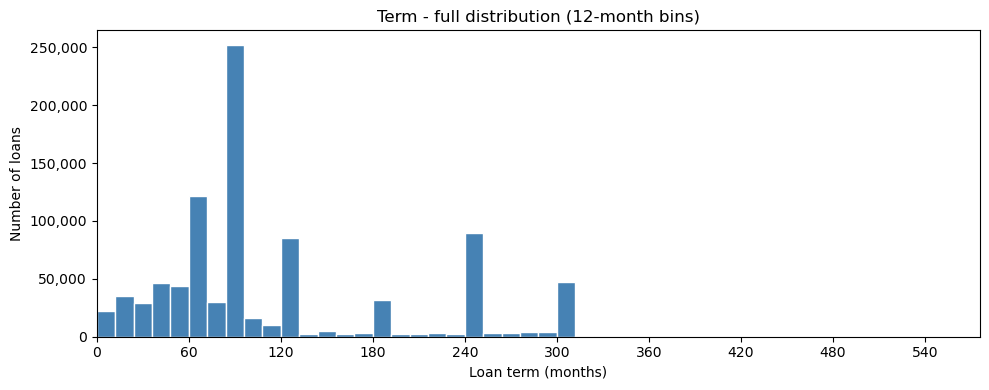

Non-missing loans: 899,164; zero-month terms: 810; maximum: 569 months. Zero-month terms need checking.


In [8]:
# Term: one bin per 12 months, covering every observed term.
term = eda["Term"].dropna()
term_bins = np.arange(0, term.max() + 12, 12)
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(term, bins=term_bins, color="steelblue", edgecolor="white")
ax.set(title="Term - full distribution (12-month bins)",
       xlabel="Loan term (months)", ylabel="Number of loans")
ax.set_xlim(0, term_bins[-1])
ax.set_xticks(np.arange(0, term_bins[-1] + 1, 60))
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
plt.tight_layout()
plt.show()
print(f"Non-missing loans: {len(term):,}; zero-month terms: {term.eq(0).sum():,}; "
      f"maximum: {term.max():,.0f} months. Zero-month terms need checking.")


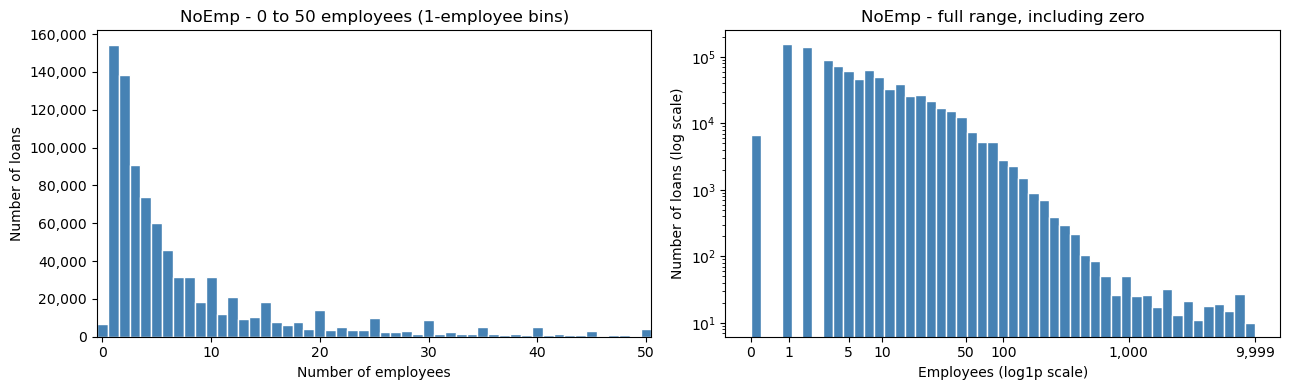

Main view: 871,813/899,164 loans (96.96%); above 50: 27,351. Full view includes all non-missing values; max = 9,999.


In [9]:
# NoEmp: single-employee bins for the main range; the second view includes the entire tail.
noemp = eda["NoEmp"].dropna()
noemp_main = noemp[noemp <= 50]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(noemp_main, bins=np.arange(-0.5, 51.5, 1), color="steelblue", edgecolor="white")
axes[0].set(title="NoEmp - 0 to 50 employees (1-employee bins)",
            xlabel="Number of employees", ylabel="Number of loans", xlim=(-0.5, 50.5))
axes[0].yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
axes[1].hist(np.log1p(noemp), bins=np.linspace(0, np.log1p(noemp.max()), 50),
             color="steelblue", edgecolor="white")
axes[1].set_xticks(np.log1p([0, 1, 5, 10, 50, 100, 1000, 9999]),
                   ["0", "1", "5", "10", "50", "100", "1,000", "9,999"])
axes[1].set_yscale("log")
axes[1].set(title="NoEmp - full range, including zero",
            xlabel="Employees (log1p scale)", ylabel="Number of loans (log scale)")
plt.tight_layout()
plt.show()
print(f"Main view: {len(noemp_main):,}/{len(noemp):,} loans ({len(noemp_main)/len(noemp):.2%}); "
      f"above 50: {noemp.gt(50).sum():,}. Full view includes all non-missing values; max = {noemp.max():,.0f}.")


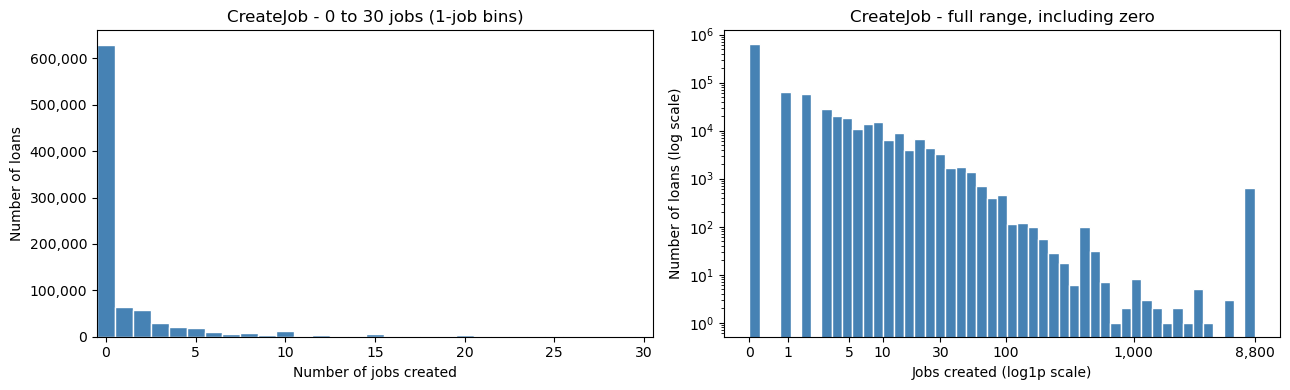

Main view: 891,274/899,164 loans (99.12%); above 30: 7,890. Zero jobs: 629,248; max = 8,800.


In [10]:
# CreateJob: keep zero jobs visible and use single-job bins in the main range.
createjob = eda["CreateJob"].dropna()
createjob_main = createjob[createjob <= 30]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(createjob_main, bins=np.arange(-0.5, 31.5, 1), color="steelblue", edgecolor="white")
axes[0].set(title="CreateJob - 0 to 30 jobs (1-job bins)",
            xlabel="Number of jobs created", ylabel="Number of loans", xlim=(-0.5, 30.5))
axes[0].yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
axes[1].hist(np.log1p(createjob), bins=np.linspace(0, np.log1p(createjob.max()), 50),
             color="steelblue", edgecolor="white")
axes[1].set_xticks(np.log1p([0, 1, 5, 10, 30, 100, 1000, 8800]),
                   ["0", "1", "5", "10", "30", "100", "1,000", "8,800"])
axes[1].set_yscale("log")
axes[1].set(title="CreateJob - full range, including zero",
            xlabel="Jobs created (log1p scale)", ylabel="Number of loans (log scale)")
plt.tight_layout()
plt.show()
print(f"Main view: {len(createjob_main):,}/{len(createjob):,} loans ({len(createjob_main)/len(createjob):.2%}); "
      f"above 30: {createjob.gt(30).sum():,}. Zero jobs: {createjob.eq(0).sum():,}; max = {createjob.max():,.0f}.")


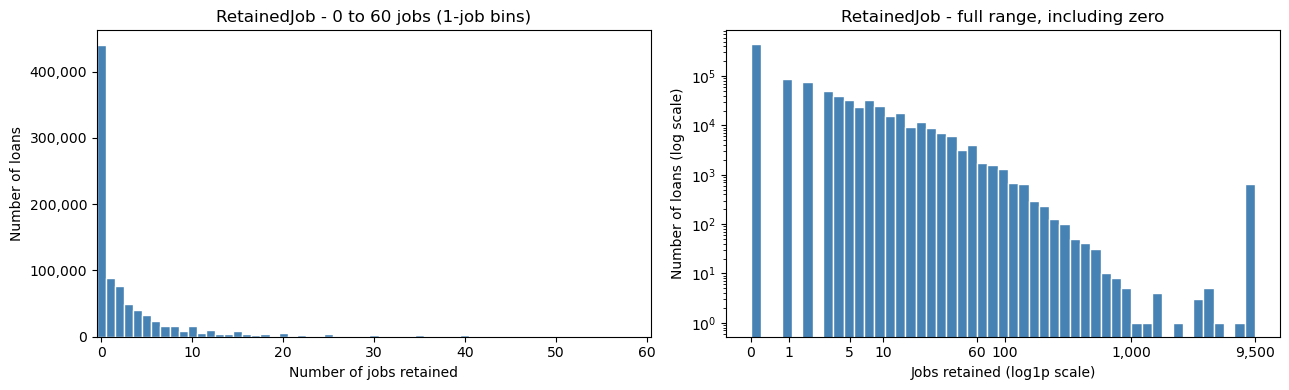

Main view: 891,651/899,164 loans (99.16%); above 60: 7,513. Zero jobs: 440,403; max = 9,500.


In [11]:
# RetainedJob: single-job bins show the concentration near zero without dropping the tail.
retainedjob = eda["RetainedJob"].dropna()
retainedjob_main = retainedjob[retainedjob <= 60]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(retainedjob_main, bins=np.arange(-0.5, 61.5, 1), color="steelblue", edgecolor="white")
axes[0].set(title="RetainedJob - 0 to 60 jobs (1-job bins)",
            xlabel="Number of jobs retained", ylabel="Number of loans", xlim=(-0.5, 60.5))
axes[0].yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
axes[1].hist(np.log1p(retainedjob), bins=np.linspace(0, np.log1p(retainedjob.max()), 50),
             color="steelblue", edgecolor="white")
axes[1].set_xticks(np.log1p([0, 1, 5, 10, 60, 100, 1000, 9500]),
                   ["0", "1", "5", "10", "60", "100", "1,000", "9,500"])
axes[1].set_yscale("log")
axes[1].set(title="RetainedJob - full range, including zero",
            xlabel="Jobs retained (log1p scale)", ylabel="Number of loans (log scale)")
plt.tight_layout()
plt.show()
print(f"Main view: {len(retainedjob_main):,}/{len(retainedjob):,} loans ({len(retainedjob_main)/len(retainedjob):.2%}); "
      f"above 60: {retainedjob.gt(60).sum():,}. Zero jobs: {retainedjob.eq(0).sum():,}; max = {retainedjob.max():,.0f}.")


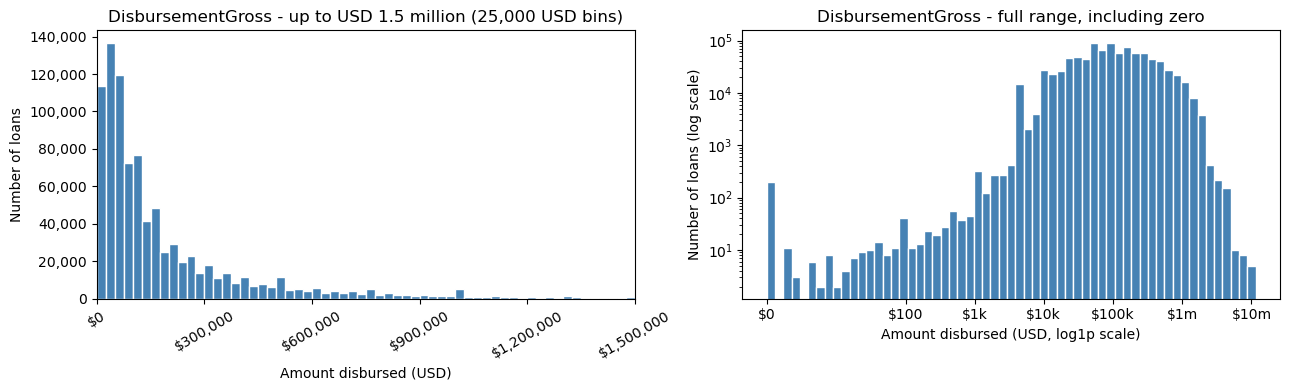

Main view: 892,959/899,164 loans (99.31%); above $1.5m: 6,205. Maximum = $11,446,325.


In [12]:
# DisbursementGross: $25,000 bins in the main range, plus every amount in the full view.
disbursement = eda["DisbursementGross"].dropna()
disbursement_main = disbursement[disbursement <= 1_500_000]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(disbursement_main, bins=np.arange(0, 1_500_001, 25_000),
             color="steelblue", edgecolor="white")
axes[0].set(title="DisbursementGross - up to USD 1.5 million (25,000 USD bins)",
            xlabel="Amount disbursed (USD)", ylabel="Number of loans", xlim=(0, 1_500_000))
axes[0].set_xticks([0, 300_000, 600_000, 900_000, 1_200_000, 1_500_000])
axes[0].xaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
axes[0].tick_params(axis="x", labelrotation=30)
axes[0].yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
axes[1].hist(np.log1p(disbursement), bins=np.linspace(0, np.log1p(disbursement.max()), 60),
             color="steelblue", edgecolor="white")
axes[1].set_xticks(np.log1p([0, 100, 1000, 10_000, 100_000, 1_000_000, 10_000_000]),
                   ["$0", "$100", "$1k", "$10k", "$100k", "$1m", "$10m"])
axes[1].set_yscale("log")
axes[1].set(title="DisbursementGross - full range, including zero",
            xlabel="Amount disbursed (USD, log1p scale)", ylabel="Number of loans (log scale)")
plt.tight_layout()
plt.show()
print(f"Main view: {len(disbursement_main):,}/{len(disbursement):,} loans ({len(disbursement_main)/len(disbursement):.2%}); "
      f"above $1.5m: {disbursement.gt(1_500_000).sum():,}. Maximum = ${disbursement.max():,.0f}.")


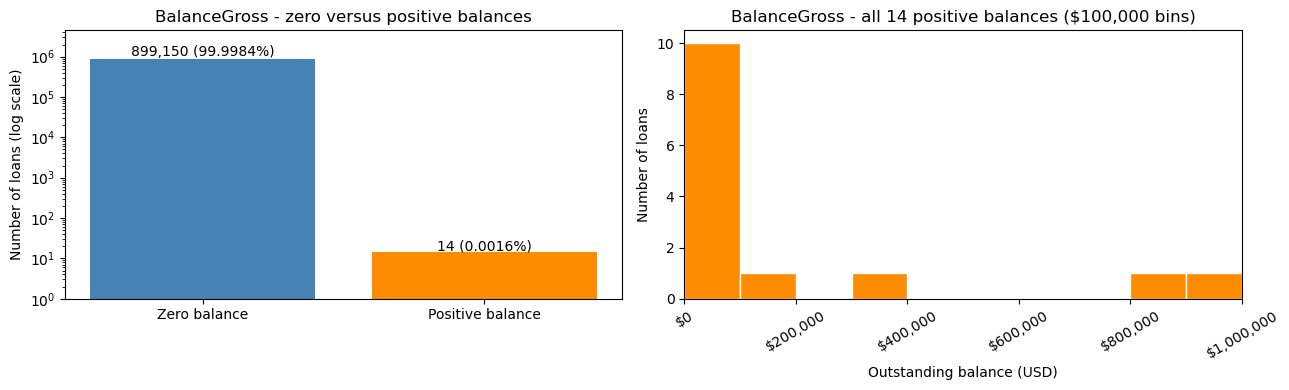

Only 14 positive balances out of 899,164 non-missing loans; positive range: $600 to $996,262. These few observations do not establish a stable distribution shape.


In [13]:
# BalanceGross: almost all values are zero; show their count separately from positive balances.
balance = eda["BalanceGross"].dropna()
balance_positive = balance[balance > 0]
balance_zero_count = balance.eq(0).sum()
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(["Zero balance", "Positive balance"], [balance_zero_count, len(balance_positive)],
            color=["steelblue", "darkorange"])
axes[0].set_yscale("log")
axes[0].set_ylim(1, len(balance) * 5)
axes[0].set(title="BalanceGross - zero versus positive balances",
            ylabel="Number of loans (log scale)")
axes[0].text(0, balance_zero_count * 1.15,
             f"{balance_zero_count:,} ({balance_zero_count/len(balance):.4%})", ha="center")
axes[0].text(1, len(balance_positive) * 1.15,
             f"{len(balance_positive):,} ({len(balance_positive)/len(balance):.4%})", ha="center")
axes[1].hist(balance_positive, bins=np.arange(0, balance_positive.max() + 100_000, 100_000),
             color="darkorange", edgecolor="white")
axes[1].set(title=f"BalanceGross - all {len(balance_positive):,} positive balances ($100,000 bins)",
            xlabel="Outstanding balance (USD)", ylabel="Number of loans", xlim=(0, 1_000_000))
axes[1].xaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
axes[1].tick_params(axis="x", labelrotation=30)
axes[1].yaxis.set_major_locator(MaxNLocator(integer=True))
plt.tight_layout()
plt.show()
print(f"Only {len(balance_positive):,} positive balances out of {len(balance):,} non-missing loans; "
      f"positive range: ${balance_positive.min():,.0f} to ${balance_positive.max():,.0f}. "
      "These few observations do not establish a stable distribution shape.")


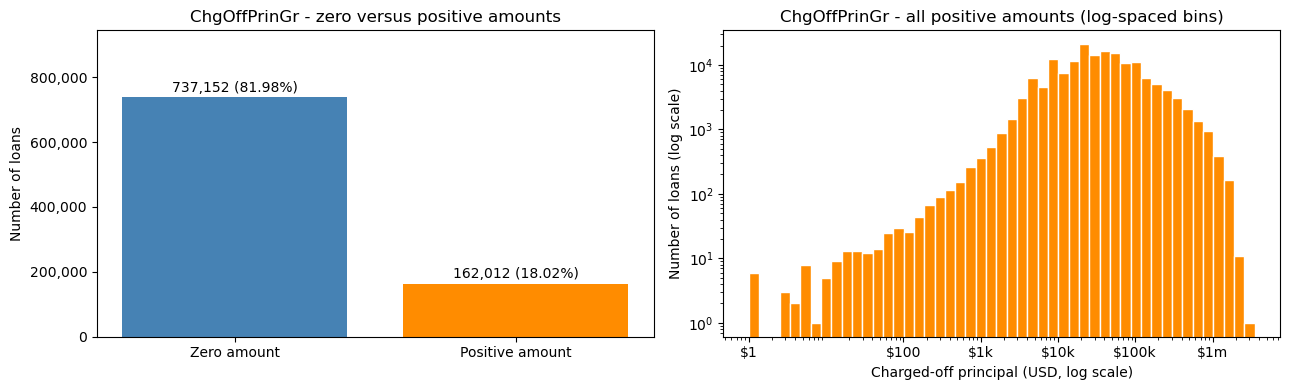

Zeros are shown separately, not discarded. Positive amounts: 162,012; range = $1 to $3,512,596.


In [14]:
# ChgOffPrinGr: separate zero amounts from the distribution of positive charged-off principal.
chargeoff = eda["ChgOffPrinGr"].dropna()
chargeoff_positive = chargeoff[chargeoff > 0]
chargeoff_zero_count = chargeoff.eq(0).sum()
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(["Zero amount", "Positive amount"], [chargeoff_zero_count, len(chargeoff_positive)],
            color=["steelblue", "darkorange"])
axes[0].set_ylim(0, len(chargeoff) * 1.05)
axes[0].set(title="ChgOffPrinGr - zero versus positive amounts", ylabel="Number of loans")
axes[0].yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
axes[0].text(0, chargeoff_zero_count + len(chargeoff) * 0.02,
             f"{chargeoff_zero_count:,} ({chargeoff_zero_count/len(chargeoff):.2%})", ha="center")
axes[0].text(1, len(chargeoff_positive) + len(chargeoff) * 0.02,
             f"{len(chargeoff_positive):,} ({len(chargeoff_positive)/len(chargeoff):.2%})", ha="center")
axes[1].hist(chargeoff_positive,
             bins=np.geomspace(chargeoff_positive.min(), chargeoff_positive.max(), 50),
             color="darkorange", edgecolor="white")
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_xticks([1, 100, 1000, 10_000, 100_000, 1_000_000],
                   ["$1", "$100", "$1k", "$10k", "$100k", "$1m"])
axes[1].set(title="ChgOffPrinGr - all positive amounts (log-spaced bins)",
            xlabel="Charged-off principal (USD, log scale)", ylabel="Number of loans (log scale)")
plt.tight_layout()
plt.show()
print(f"Zeros are shown separately, not discarded. Positive amounts: {len(chargeoff_positive):,}; "
      f"range = ${chargeoff_positive.min():,.0f} to ${chargeoff_positive.max():,.0f}.")


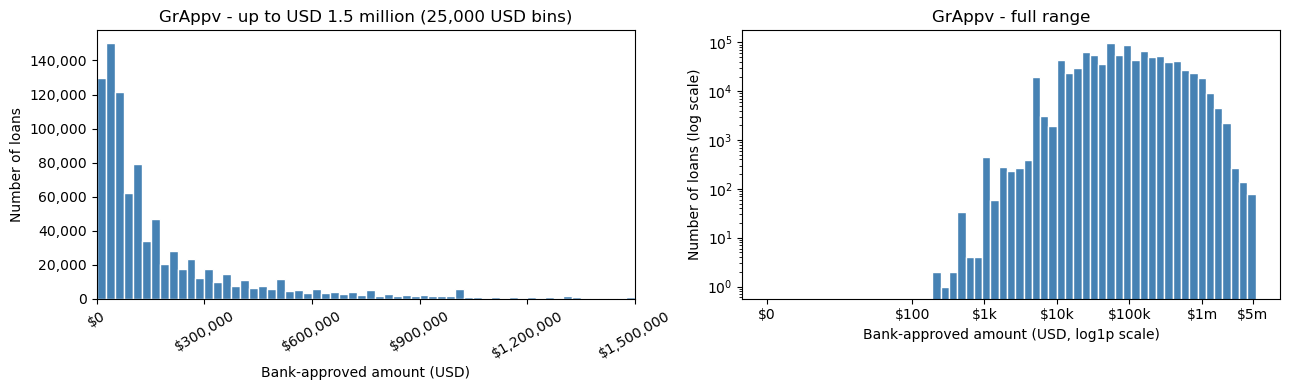

Main view: 893,206/899,164 loans (99.34%); above $1.5m: 5,958. Maximum = $5,472,000.


In [15]:
# GrAppv: use $25,000 bins where most approvals fall and retain the full range alongside.
grappv = eda["GrAppv"].dropna()
grappv_main = grappv[grappv <= 1_500_000]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(grappv_main, bins=np.arange(0, 1_500_001, 25_000), color="steelblue", edgecolor="white")
axes[0].set(title="GrAppv - up to USD 1.5 million (25,000 USD bins)",
            xlabel="Bank-approved amount (USD)", ylabel="Number of loans", xlim=(0, 1_500_000))
axes[0].set_xticks([0, 300_000, 600_000, 900_000, 1_200_000, 1_500_000])
axes[0].xaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
axes[0].tick_params(axis="x", labelrotation=30)
axes[0].yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
axes[1].hist(np.log1p(grappv), bins=np.linspace(0, np.log1p(grappv.max()), 60),
             color="steelblue", edgecolor="white")
axes[1].set_xticks(np.log1p([0, 100, 1000, 10_000, 100_000, 1_000_000, 5_000_000]),
                   ["$0", "$100", "$1k", "$10k", "$100k", "$1m", "$5m"])
axes[1].set_yscale("log")
axes[1].set(title="GrAppv - full range",
            xlabel="Bank-approved amount (USD, log1p scale)", ylabel="Number of loans (log scale)")
plt.tight_layout()
plt.show()
print(f"Main view: {len(grappv_main):,}/{len(grappv):,} loans ({len(grappv_main)/len(grappv):.2%}); "
      f"above $1.5m: {grappv.gt(1_500_000).sum():,}. Maximum = ${grappv.max():,.0f}.")


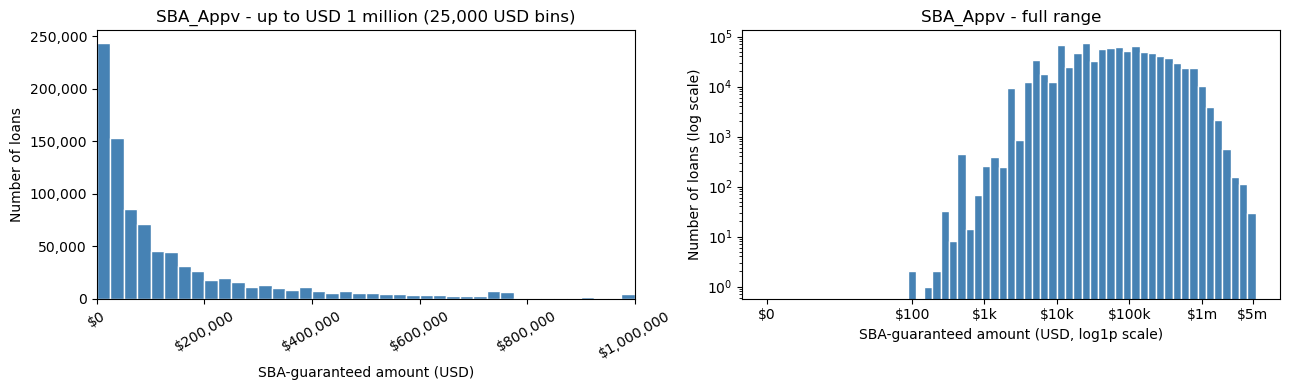

Main view: 890,387/899,164 loans (99.02%); above $1m: 8,777. Maximum = $5,472,000.


In [16]:
# SBA_Appv: a separate $1 million main view reflects its smaller typical amounts.
sbaappv = eda["SBA_Appv"].dropna()
sbaappv_main = sbaappv[sbaappv <= 1_000_000]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(sbaappv_main, bins=np.arange(0, 1_000_001, 25_000), color="steelblue", edgecolor="white")
axes[0].set(title="SBA_Appv - up to USD 1 million (25,000 USD bins)",
            xlabel="SBA-guaranteed amount (USD)", ylabel="Number of loans", xlim=(0, 1_000_000))
axes[0].set_xticks([0, 200_000, 400_000, 600_000, 800_000, 1_000_000])
axes[0].xaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
axes[0].tick_params(axis="x", labelrotation=30)
axes[0].yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
axes[1].hist(np.log1p(sbaappv), bins=np.linspace(0, np.log1p(sbaappv.max()), 60),
             color="steelblue", edgecolor="white")
axes[1].set_xticks(np.log1p([0, 100, 1000, 10_000, 100_000, 1_000_000, 5_000_000]),
                   ["$0", "$100", "$1k", "$10k", "$100k", "$1m", "$5m"])
axes[1].set_yscale("log")
axes[1].set(title="SBA_Appv - full range",
            xlabel="SBA-guaranteed amount (USD, log1p scale)", ylabel="Number of loans (log scale)")
plt.tight_layout()
plt.show()
print(f"Main view: {len(sbaappv_main):,}/{len(sbaappv):,} loans ({len(sbaappv_main)/len(sbaappv):.2%}); "
      f"above $1m: {sbaappv.gt(1_000_000).sum():,}. Maximum = ${sbaappv.max():,.0f}.")


Large values are not always errors. We need to check them before removing them. Values such as 999 may be real values or placeholders. Zero jobs created can be valid, but a zero loan term or a negative amount needs checking. When most values are zero, the IQR rule may flag many valid values.

## 3. Categorical Columns in Dataset

### Summary of categorical columns
We count the different values in each column and show the five most common ones. We also count categories with fewer than 100 loans. Rare categories may be grouped later if this makes sense for the analysis.

In [17]:
categorical_cols = []
for col in sba_df.columns:
    if col not in numeric_cols and col not in date_cols:
        categorical_cols.append(col)

for col in categorical_cols:
    counts = eda[col].value_counts()
    print("Column:", col)
    print("The number of different values:", eda[col].nunique())
    print("The number of categories with fewer than 100 loans:", (counts < 100).sum())
    display(eda[col].value_counts(dropna=False).head(5))

# Check the labels used in the main category columns.
allowed = {
    "NewExist": ["1", "2"],
    "UrbanRural": ["0", "1", "2"],
    "RevLineCr": ["Y", "N"],
    "LowDoc": ["Y", "N"],
    "MIS_Status": ["P I F", "CHGOFF"]
}
for col, valid_values in allowed.items():
    unexpected = eda[col].notna() & ~eda[col].isin(valid_values)
    print("Unexpected labels in", col)
    display(eda.loc[unexpected, col].value_counts())

# Compare labels before and after removing spaces and using uppercase.
for col in ["Name", "City", "Bank"]:
    cleaned = eda[col].str.upper().str.replace(r"\s+", " ", regex=True)
    print(col, "- fewer labels after cleaning:", eda[col].nunique() - cleaned.nunique())


Column: LoanNr_ChkDgt
The number of different values: 899164
The number of categories with fewer than 100 loans: 899164


LoanNr_ChkDgt
9996003010    1
1000014003    1
1000024006    1
1000034009    1
1000044001    1
Name: count, dtype: int64

Column: Name
The number of different values: 779583
The number of categories with fewer than 100 loans: 779541


Name
SUBWAY                 1269
QUIZNO'S SUBS           433
COLD STONE CREAMERY     366
QUIZNO'S                345
DOMINO'S PIZZA          329
Name: count, dtype: int64

Column: City
The number of different values: 32581
The number of categories with fewer than 100 loans: 30914


City
LOS ANGELES    11558
HOUSTON        10247
NEW YORK        7846
CHICAGO         6036
MIAMI           5594
Name: count, dtype: int64

... (31 outputs left out)

LowDoc
0    1491
C     758
S     603
A     497
R      75
1       1
Name: count, dtype: int64

Unexpected labels in MIS_Status


Series([], Name: count, dtype: int64)

Name - fewer labels after cleaning: 7468
City - fewer labels after cleaning: 7820
Bank - fewer labels after cleaning: 0


### Distribution of category values
We show the counts and percentages for the main business and program categories, including loan status. Missing values are shown as a separate group. This helps us see which categories are common and whether some categories are much larger than others.

NewExist


,Number of loans,Percentage
NewExist,,
1,644869,71.72
2,253125,28.15
0,1034,0.11
Missing,136,0.02


UrbanRural


,Number of loans,Percentage
UrbanRural,,
1,470654,52.34
0,323167,35.94
2,105343,11.72


RevLineCr


,Number of loans,Percentage
RevLineCr,,
N,420288,46.74
0,257602,28.65
Y,201397,22.40
T,15284,1.70
Missing,4528,0.50
1,23,0.00
R,14,0.00
`,11,0.00
2,6,0.00


LowDoc


,Number of loans,Percentage
LowDoc,,
N,782822,87.06
Y,110335,12.27
Missing,2582,0.29
0,1491,0.17
C,758,0.08
S,603,0.07
A,497,0.06
R,75,0.01
1,1,0.00


MIS_Status


,Number of loans,Percentage
MIS_Status,,
P I F,739609,82.26
CHGOFF,157558,17.52
Missing,1997,0.22


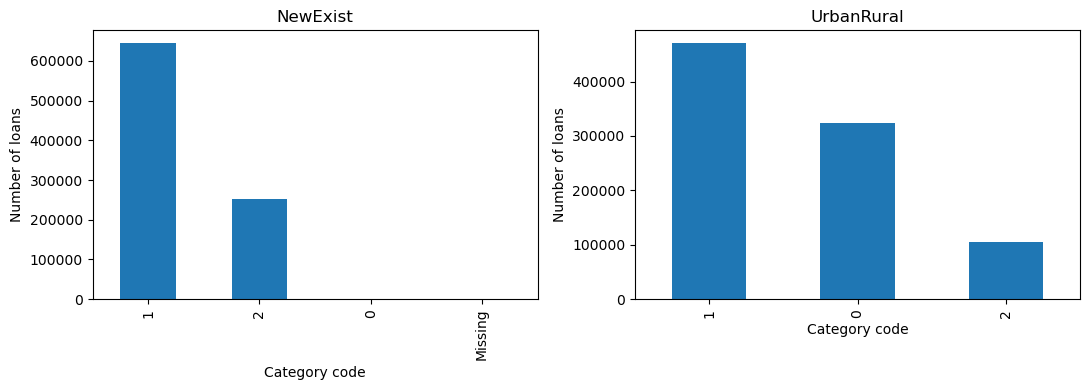

In [18]:
for col in ["NewExist", "UrbanRural", "RevLineCr", "LowDoc", "MIS_Status"]:
    counts = eda[col].fillna("Missing").value_counts()
    category_summary = pd.DataFrame({
        "Number of loans": counts,
        "Percentage": counts / len(eda) * 100
    })
    print(col)
    display(category_summary.round(2))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col in zip(axes, ["NewExist", "UrbanRural"]):
    eda[col].fillna("Missing").value_counts().plot.bar(ax=ax)
    ax.set_title(col)
    ax.set_xlabel("Category code")
    ax.set_ylabel("Number of loans")
plt.tight_layout()
plt.show()


## 4. Missing Data

### Number and percentage of missing values
We compare missing values in the original data with missing values after removing blank text and converting columns. Unknown codes are counted separately because they are not empty cells.

A paid loan usually does not need a charge-off date. We check missing dates together with the loan outcome.

In [19]:
missing = pd.DataFrame({
    "Original missing": sba_df.isna().sum(),
    "Missing after conversion": eda[sba_df.columns].isna().sum()
})
missing["Missing percentage"] = missing["Missing after conversion"] / len(eda) * 100
display(missing.sort_values("Missing percentage", ascending=False).round(2))

# Mark missing values and unknown codes for the pattern checks below.
unusable = eda[sba_df.columns].isna().copy()
for col, valid_values in allowed.items():
    unusable[col] = ~eda[col].isin(valid_values)
valid_industry = eda["NAICS"].str.fullmatch(r"\d{2,6}", na=False) & eda["NAICS"].ne("0")
unusable["NAICS"] = ~valid_industry
unusable["UrbanRural"] = ~eda["UrbanRural"].isin(["1", "2"])
unusable["ApprovalFY"] = ~valid_year
print("Number of missing or unknown values:")
display(unusable.sum())

display(pd.crosstab(
    eda["MIS_Status"].fillna("Missing outcome"),
    eda["ChgOffDate"].isna(),
    colnames=["Charge-off date is missing"]
))


,Original missing,Missing after conversion,Missing percentage
ChgOffDate,736465,736465,81.91
RevLineCr,4528,4528,0.50
LowDoc,2582,2582,0.29
DisbursementDate,2368,2368,0.26
MIS_Status,1997,1997,0.22
BankState,1566,1566,0.17
Bank,1559,1559,0.17
NewExist,136,136,0.02
City,30,30,0.00
State,14,14,0.00


Number of missing or unknown values:


LoanNr_ChkDgt             0
Name                     14
City                     30
State                    14
Zip                       0
Bank                   1559
BankState              1566
NAICS                201948
ApprovalDate              0
ApprovalFY               18
Term                      0
NoEmp                     0
NewExist               1170
CreateJob                 0
RetainedJob               0
FranchiseCode             0
UrbanRural           323167
RevLineCr            277479
LowDoc                 6007
ChgOffDate           736465
DisbursementDate       2368
DisbursementGross         0
BalanceGross              0
MIS_Status             1997
ChgOffPrinGr              0
GrAppv                    0
SBA_Appv                  0
dtype: int64

Charge-off date is missing,False,True
MIS_Status,,
CHGOFF,157511,47
Missing outcome,261,1736
P I F,4927,734682


### Patterns of missing values
We compare the percentage of missing or unknown values by loan outcome and approval decade. Different percentages may suggest changes in how the data was collected. These tables cannot tell us the exact reason why values are missing.

In [20]:
pattern_cols = ["NAICS", "NewExist", "UrbanRural", "RevLineCr", "LowDoc", "DisbursementDate"]
status_group = eda["MIS_Status"].fillna("Missing outcome")
approval_decade = (eda["ApprovalYear"] // 10) * 10

print("Missing or unknown percentage by outcome:")
display((unusable[pattern_cols].groupby(status_group).mean() * 100).round(2))
print("Missing or unknown percentage by approval decade:")
display((unusable[pattern_cols].groupby(approval_decade).mean() * 100).round(2))


Missing or unknown percentage by outcome:


,NAICS,NewExist,UrbanRural,RevLineCr,LowDoc,DisbursementDate
MIS_Status,,,,,,
CHGOFF,10.66,0.05,14.58,28.67,1.0,0.21
Missing outcome,14.07,0.40,17.08,11.22,0.4,9.66
P I F,25.00,0.15,40.54,31.38,0.6,0.25


Missing or unknown percentage by approval decade:


,NAICS,NewExist,UrbanRural,RevLineCr,LowDoc,DisbursementDate
ApprovalYear,,,,,,
1960.0,100.00,90.91,100.00,0.00,0.00,54.55
1970.0,100.00,0.00,100.00,0.00,0.00,1.74
1980.0,72.48,0.19,100.00,0.00,0.00,0.79
1990.0,54.33,0.15,95.02,22.95,0.55,0.08
2000.0,3.14,0.10,1.32,39.09,0.56,0.28
2010.0,0.01,0.36,0.00,2.18,3.63,1.09


### Plan for missing values
We do not fill or remove values in this section. The table gives a plan for the cleaning step. We should check why a value is missing before deciding how to handle it.

In [21]:
handling = pd.DataFrame({
    "Columns": [
        "MIS_Status", "ChgOffDate", "Other dates and ApprovalFY",
        "Category columns", "Numerical columns", "LoanNr_ChkDgt",
        "ChgOffPrinGr and BalanceGross"
    ],
    "Plan": [
        "Keep the outcome as unknown; do not assume that the loan was paid.",
        "Leave empty for paid loans; check missing dates for charged-off loans.",
        "Check the source; do not invent replacement dates or years.",
        "Use an Unknown category after checking unusual codes.",
        "Check the source before deciding whether to fill or leave missing values.",
        "Check missing IDs; do not invent replacement loan IDs.",
        "Check the source; do not assume a missing amount is zero."
    ]
})
display(handling)


,Columns,Plan
0,MIS_Status,Keep the outcome as unknown; do not assume tha...
1,ChgOffDate,Leave empty for paid loans; check missing date...
2,Other dates and ApprovalFY,Check the source; do not invent replacement da...
3,Category columns,Use an Unknown category after checking unusual...
4,Numerical columns,Check the source before deciding whether to fi...
5,LoanNr_ChkDgt,Check missing IDs; do not invent replacement l...
6,ChgOffPrinGr and BalanceGross,Check the source; do not assume a missing amou...


## 5. Relationships

### Correlation between numerical columns
Correlation shows how two columns change together. Values near 1 mean they tend to increase together. Values near -1 mean one tends to decrease as the other increases.

Pearson looks at linear relationships. Spearman compares the order of values and can help with very uneven distributions. Correlation does not prove that one variable causes another.

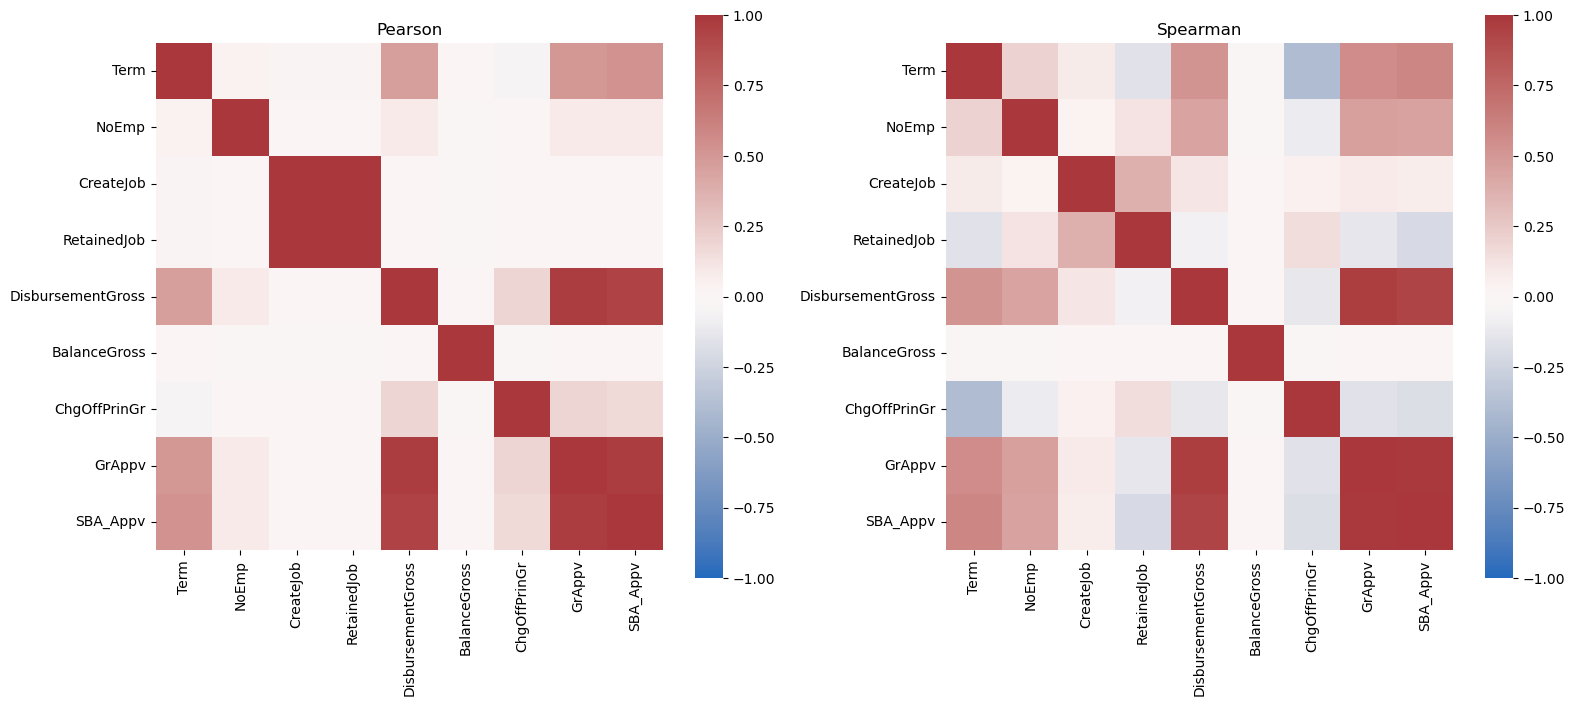

In [22]:
pearson = eda[numeric_cols].corr(method="pearson")
spearman = eda[numeric_cols].corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, matrix, title in zip(axes, [pearson, spearman], ["Pearson", "Spearman"]):
    sns.heatmap(matrix, ax=ax, cmap="vlag", center=0, vmin=-1, vmax=1, square=True)
    ax.set_title(title)
plt.tight_layout()
plt.show()


### Numerical values by business category
We compare the median approved amount, loan term and employee count across business and program categories. We also show the number of loans in each group. These tables describe general differences between groups.

In [23]:
for col in ["NewExist", "UrbanRural", "RevLineCr", "LowDoc"]:
    grouped = eda.groupby(col, dropna=False)
    result = pd.DataFrame({
        "Number of loans": grouped.size(),
        "Median approved amount": grouped["GrAppv"].median(),
        "Median term (months)": grouped["Term"].median(),
        "Median employee count": grouped["NoEmp"].median()
    })
    print("Grouped by", col)
    display(result.round(2))

print("Business type and urban/rural category:")
display(pd.crosstab(
    eda["NewExist"].fillna("Missing"),
    eda["UrbanRural"].fillna("Missing")
))


Grouped by NewExist


,Number of loans,Median approved amount,Median term (months),Median employee count
NewExist,,,,
0,1034,215000.0,120.0,8.0
1,644869,100000.0,84.0,5.0
2,253125,75000.0,84.0,2.0
NaN,136,69750.0,84.0,4.0


Grouped by UrbanRural


,Number of loans,Median approved amount,Median term (months),Median employee count
UrbanRural,,,,
0,323167,126000.0,108.0,6.0
1,470654,53000.0,84.0,4.0
2,105343,75000.0,84.0,4.0


Grouped by RevLineCr


,Number of loans,Median approved amount,Median term (months),Median employee count
RevLineCr,,,,
",",1,6000.0,60.0,1.0
-,1,54000.0,90.0,1.0
.,1,15000.0,12.0,3.0
0,257602,125900.0,84.0,4.0
1,23,165000.0,108.0,7.0
2,6,378000.0,12.0,5.0
3,1,480250.0,300.0,7.0
4,1,867000.0,240.0,26.0
5,1,275000.0,240.0,6.0


Grouped by LowDoc


,Number of loans,Median approved amount,Median term (months),Median employee count
LowDoc,,,,
0,1491,275000.0,239.0,8.0
1,1,797345.0,252.0,5.0
A,497,75000.0,61.0,3.0
C,758,243000.0,120.0,10.0
N,782822,100000.0,84.0,5.0
R,75,50000.0,64.0,2.0
S,603,25000.0,84.0,2.0
Y,110335,60000.0,84.0,3.0
NaN,2582,42950.0,84.0,2.0


Business type and urban/rural category:


UrbanRural,0,1,2
NewExist,,,
0,514,364,156
1,234581,340080,70208
2,88072,130103,34950
Missing,0,107,29


### Number of loans over time
We count loans by approval fiscal year to understand the time coverage of the dataset. Years that could not be converted are not included in this chart. Unusual years are kept visible so they can be checked against the source.

,Number of loans
ApprovalYear,
1962.0,1
1965.0,1
1966.0,1
1967.0,2
1968.0,2
1969.0,4
1970.0,8
1971.0,20
1972.0,27


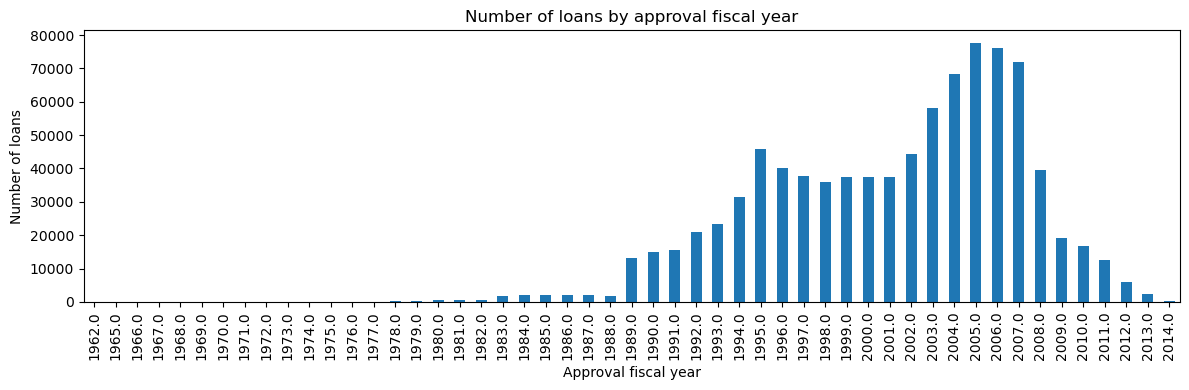

Loans without a valid four-digit fiscal year: 18


In [24]:
year_counts = eda["ApprovalYear"].value_counts().sort_index()
display(year_counts.rename("Number of loans").to_frame())
year_counts.plot.bar(figsize=(12, 4))
plt.title("Number of loans by approval fiscal year")
plt.xlabel("Approval fiscal year")
plt.ylabel("Number of loans")
plt.tight_layout()
plt.show()
print("Loans without a valid four-digit fiscal year:", (~valid_year).sum())


## 6. Key Observations and Preprocessing Plan

### Key observations
The following results summarize the dataset's size, missing values, numerical values, category balance and time coverage.

In [25]:
print(f"1. The dataset has {n_rows:,} rows and {n_cols} columns.")
print(f"   There are {duplicate_count:,} duplicate rows and {empty_count:,} empty rows.")
print("2. Columns with the most missing values after conversion:")
display(missing.sort_values("Missing percentage", ascending=False).head(5))
print("3. Mean and median of numerical columns (50% is the median):")
display(summary[["mean", "50%", "min", "max"]].round(2))
print("4. The dataset has unknown codes in some category columns.")
print(f"   Unspecified industry codes: {eda['NAICS'].eq('0').sum():,}")
print(f"   Unknown urban/rural codes: {eda['UrbanRural'].eq('0').sum():,}")
print("   Loan status counts:")
display(eda["MIS_Status"].value_counts(dropna=False))
print(f"5. Valid four-digit fiscal years range from {eda['ApprovalYear'].min():.0f} to {eda['ApprovalYear'].max():.0f}.")
print(f"   There are {(~valid_year).sum():,} missing or nonstandard fiscal-year values to check.")


1. The dataset has 899,164 rows and 27 columns.
   There are 0 duplicate rows and 0 empty rows.
2. Columns with the most missing values after conversion:


,Original missing,Missing after conversion,Missing percentage
ChgOffDate,736465,736465,81.905526
RevLineCr,4528,4528,0.503579
LowDoc,2582,2582,0.287156
DisbursementDate,2368,2368,0.263356
MIS_Status,1997,1997,0.222095


3. Mean and median of numerical columns (50% is the median):


,mean,50%,min,max
Term,110.77,84.0,0.0,569.0
NoEmp,11.41,4.0,0.0,9999.0
CreateJob,8.43,0.0,0.0,8800.0
RetainedJob,10.80,1.0,0.0,9500.0
DisbursementGross,201154.02,100000.0,0.0,11446325.0
BalanceGross,2.99,0.0,0.0,996262.0
ChgOffPrinGr,13503.30,0.0,0.0,3512596.0
GrAppv,192686.98,90000.0,200.0,5472000.0
SBA_Appv,149488.79,61250.0,100.0,5472000.0


4. The dataset has unknown codes in some category columns.
   Unspecified industry codes: 201,948
   Unknown urban/rural codes: 323,167
   Loan status counts:


MIS_Status
P I F     739609
CHGOFF    157558
NaN         1997
Name: count, dtype: int64

5. Valid four-digit fiscal years range from 1962 to 2014.
   There are 18 missing or nonstandard fiscal-year values to check.


### Data quality issues and preprocessing plan

| Issue | Plan |
| --- | --- |
| Duplicate or empty rows | Remove empty rows and confirmed duplicates if found. Check repeated loan IDs first. |
| Money and date columns | Convert their types and check failed conversions, unusual years and dates in the wrong order. Do not guess a replacement year. |
| Very large, negative or zero values | Check whether they are real before removing or changing them. |
| Inconsistent category labels | Remove extra spaces, standardize letter case and check unusual codes. Group rare categories when useful. |
| Missing values | Follow the missing-value plan above and record how many rows are affected. |
| Outcome conflicts | Check paid loans with charge-off amounts and charged-off loans with missing dates or amounts. |
| IDs and category codes | Keep them as text. Keep IDs for identifying records; do not treat them as numerical measurements. |
| Columns to keep or drop | Keep the original columns during exploration. Decide which columns are useful for each later analysis. |

### General patterns to explore further

- Large differences between the mean and median may suggest uneven numerical distributions.
- Rare categories and unknown codes may need extra care during cleaning.
- Strong correlations between money columns may mean they contain similar information.
- Changes in record counts and missing values over time may reflect changes in data collection.

We keep the original data unchanged. The final cleaning decisions will be made in the preprocessing step.